##### Git

In [4]:
!git config --global user.name "WalterOuO"
!git config --global user.email "walterlai@gapp.nthu.edu.tw"

In [ ]:
# !git rm -r --cached . # 不要隨便用, 會把過去git紀錄全清空

# 如果要強制修改上一次push的所有file的commit：用--amend，push 尾巴加上 -f
# !git commit --amend -m "Initial Commit"

# 如果上一次push的file只有一個檔案要修改commit:
# !git reset HEAD~1 --soft   # 用 reset 把上一次的紀錄打開: HEAD~1就是上一次, HEAD~2就是上兩次
# !git reset HEAD .      # 把所有檔案先移出暫存區
# !git add .          # 再把上次push的所有檔案加進去
# !git reset somefile     # 唯獨把要修改commit的檔案移出暫存區
# !git commit -m "原本commit" # 把不用改的檔案commit就寫原本commit
# !git add app/.qdrant-initialized # 再把要改的檔案加入暫存區
# !git commit -m "new commit" # 再單獨修改它的新commit
# !git push -u origin main -f # 強制覆蓋線上的錯誤紀錄

In [ ]:
# feat	 新增功能 (Feature)
# fix	  修復 Bug (Bug Fix)
# docs	 僅修改文件 (Documentation)
# style	 不影響程式碼運作的格式調整（如空格、分號、缩排）
# refactor 輸出不變時重構程式碼（既不是新增功能，也不是修補 Bug）
# perf	 效能優化 (Performance)
# test	 增加或修改測試代碼 (Test)
# chore	 建構流程或輔助工具的變動（如 CI/CD、套件版號更新）
# revert	撤銷先前的 commit

In [ ]:
!git add .
!git pull origin main --rebase

In [6]:
!git add results/charts/day1_awq_comparison.png results/charts/day3_apc_comparison.png
!git commit -m "style(chart): adjust y-axis limits to prevent text clipping in day1 and day3 plots"
!git push

[main 907d89e] style(chart): adjust y-axis limits to prevent text clipping in day1 and day3 plots
 2 files changed, 0 insertions(+), 0 deletions(-)
To https://github.com/WalterOuO/five-day-vllm-inference-optimization-practice.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/WalterOuO/five-day-vllm-inference-optimization-practice.git'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


### 環境初始化

##### 掛載Google Drive

In [5]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/vllm-inference-optimization

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/vllm-inference-optimization


##### 環境檢查

In [ ]:
!nvidia-smi
import sys
print("Python:", sys.version)
import torch
print(f"CUDA 是否可用: {torch.cuda.is_available()}")
if torch.cuda.is_available():
  print(f"GPU 型號: {torch.cuda.get_device_name(0)}")
  print("Torch:", torch.__version__)
  print("Torch CUDA:", torch.version.cuda)
  print(f"VRAM 總容量: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Tue Oct 27 11:59:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

##### 安裝依賴套件

In [ ]:
!pip install -r requirements.txt

print("✅ 所有依賴套件已完成安裝！")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 MB 58.9 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 526.6/526.6 MB 53.6 MB/s  0:00:07
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 85.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 85.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 102.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 46.5 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 61.9 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 112.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 89.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 MB 52.6 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.0/92.0 MB 57.0 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.0/206.0 MB 56.8 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 42.2 MB/s  0:00:00
   ━━━

✅ 所有依賴套件已完成安裝！


### Day 1: model weight AWQ to fp8

##### 執行Baseline實驗

In [ ]:
!python src/experiments/day1_awq_runner.py --mode baseline --config configs/day1_awq.yaml

========== 啟動 Day 1 實驗: BASELINE ==========
模型 ID: Qwen/Qwen2.5-3B-Instruct
Prompt 來源: data/prompts/benchmark_prompts.json
config.json: 100% 661/661 [00:00<00:00, 3.35MB/s]
🔍 [動態模型結構解析] 總參數量: 3.40 B (3,396,861,952 params)
🔍 [動態權重計算] 理論模型權重佔用: 6.33 GB
🚀 成功載入 30 個內容獨立的 Prompts (高併發壓測)
(MainProcess pid=5344) INFO 10-21 14:30:15 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'float16', 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=5344) INFO 10-21 14:30:35 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=5344) WARNING 10-21 14:30:35 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=5344) INFO 10-21 14:30:35 [model.py:2152] Using max model len 32768
(MainProcess pid=5344) INFO 10-21 14:30:35 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
model.safetensors.index.json: 100% 35.6k/35.6k [00:00<00:00, 93.0MB/s]
Parse safete

##### 執行優化實驗

In [ ]:
!python src/experiments/day1_awq_runner.py --mode awq --config configs/day1_awq.yaml

========== 啟動 Day 1 實驗: AWQ ==========
模型 ID: Qwen/Qwen2.5-3B-Instruct-AWQ
Prompt 來源: data/prompts/benchmark_prompts.json
config.json: 100% 839/839 [00:00<00:00, 4.43MB/s]
🔍 [動態模型結構解析] 總參數量: 3.40 B (3,396,861,952 params)
🔍 [動態權重計算] 理論模型權重佔用: 1.82 GB
🚀 成功載入 30 個內容獨立的 Prompts (高併發壓測)
(MainProcess pid=6810) INFO 10-21 14:34:54 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'float16', 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'quantization': 'awq', 'model': 'Qwen/Qwen2.5-3B-Instruct-AWQ'}
(MainProcess pid=6810) INFO 10-21 14:34:56 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=6810) INFO 10-21 14:34:56 [model.py:2152] Using max model len 32768
(MainProcess pid=6810) INFO 10-21 14:34:58 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=6810) INFO 10-21 14:35:02 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_a

##### 生成圖表對比

====================== Day 1 實驗對照總結 ======================
    mode                        model  concurrency  model_weight_vram_gb  kv_cache_pool_vram_gb  total_reserved_vram_gb  system_tps
baseline     Qwen/Qwen2.5-3B-Instruct           30                  6.33                   5.73                   12.06      279.65
     awq Qwen/Qwen2.5-3B-Instruct-AWQ           30                  1.82                  10.26                   12.08      330.54


/tmp/ipykernel_1076/1756097730.py:63: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1076/1756097730.py:63: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1076/1756097730.py:65: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/tmp/ipykernel_1076/1756097730.py:65: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


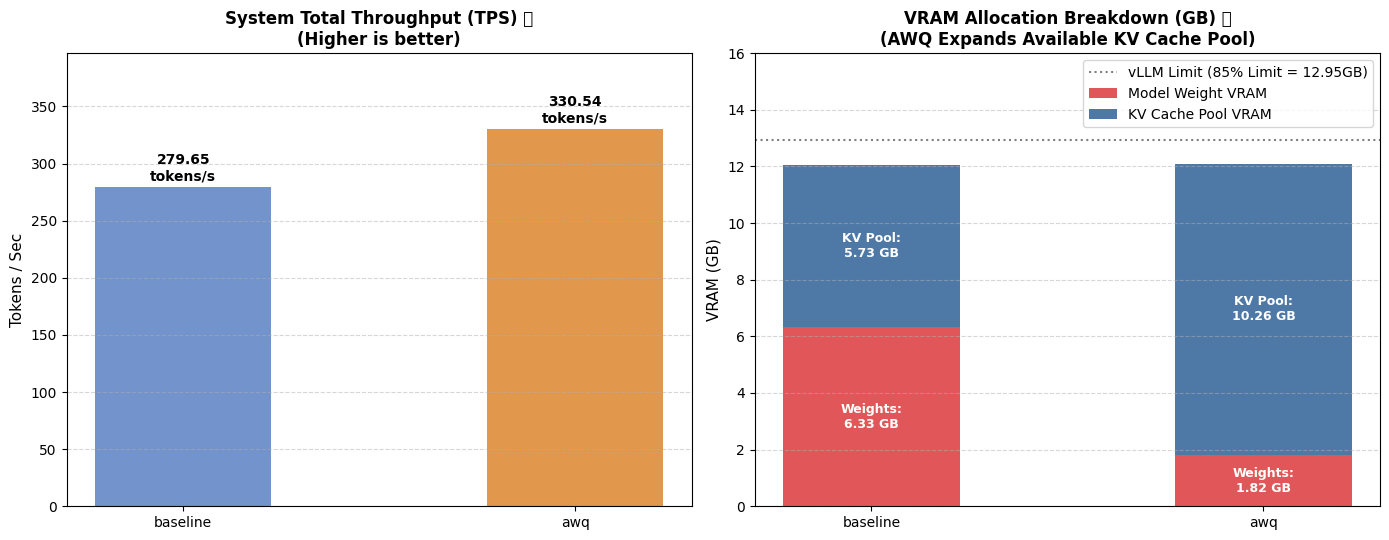


📊 高級視覺化圖表已儲存至: results/charts/day1_awq_comparison.png


In [2]:
# Cell 7: [Report & Visualization] 生成結構化 VRAM 拆解與 TPS 吞吐量對比圖表

import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. 讀取兩組實驗的 JSON 結果
with open("results/raw_logs/day1_baseline.json", "r", encoding="utf-8") as f:
    baseline_res = json.load(f)

with open("results/raw_logs/day1_awq.json", "r", encoding="utf-8") as f:
    awq_res = json.load(f)

df = pd.DataFrame([baseline_res, awq_res])

# 2. 印出文字版摘要對照表 (包含動態拆解指標)
print("====================== Day 1 實驗對照總結 ======================")
summary_cols = ["mode", "model", "concurrency", "model_weight_vram_gb", "kv_cache_pool_vram_gb", "total_reserved_vram_gb", "system_tps"]
print(df[summary_cols].to_string(index=False))

# 3. 繪製對比圖表 (左圖：TPS 吞吐量 / 右圖：VRAM 堆疊結構)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 圖 1: System TPS 對比 (越大越好)
bars = axes[0].bar(df['mode'], df['system_tps'], color=['#7293CB', '#E1974C'], width=0.45)
axes[0].set_title('System Total Throughput (TPS) 🚀\n(Higher is better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Tokens / Sec', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

max_tps = df['system_tps'].max()
axes[0].set_ylim(0, max_tps * 1.20)

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + 3,
                f"{height:.2f}\ntokens/s", ha='center', va='bottom', fontweight='bold')

# 圖 2: VRAM 堆疊結構圖 (顯示模型權重與 KV Cache Pool 的消長)
modes = df['mode']
weight_vram = df['model_weight_vram_gb']
kv_pool_vram = df['kv_cache_pool_vram_gb']

# 繪製堆疊柱狀圖 (Model Weights 在下，KV Cache Pool 在上)
p1 = axes[1].bar(modes, weight_vram, width=0.45, label='Model Weight VRAM', color='#E15759')
p2 = axes[1].bar(modes, kv_pool_vram, width=0.45, bottom=weight_vram, label='KV Cache Pool VRAM', color='#4E79A7')

axes[1].set_title('VRAM Allocation Breakdown (GB) 📊\n(AWQ Expands Available KV Cache Pool)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('VRAM (GB)', fontsize=11)
axes[1].set_ylim(0, 16) # 設定最高為 T4 顯存上限 15-16GB
axes[1].axhline(y=12.95, color='gray', linestyle=':', label='vLLM Limit (85% Limit = 12.95GB)')
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# 在柱狀圖上標註數值
for i in range(len(df)):
    # 標註模型權重 GB
    axes[1].text(i, weight_vram[i]/2, f"Weights:\n{weight_vram[i]} GB",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    # 標註 KV Cache Pool GB
    axes[1].text(i, weight_vram[i] + kv_pool_vram[i]/2, f"KV Pool:\n{kv_pool_vram[i]} GB",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
chart_path = "results/charts/day1_awq_comparison.png"
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"\n📊 高級視覺化圖表已儲存至: {chart_path}")

### Day 2: Chunked Prefill
> Day 2 從 KV cache量化改成 Chunked Prefill,   
因為 colab T4 GPU不支援把 KV cache從 FP16量化到 FP8，

##### 執行 Baseline 實驗

In [ ]:
!python src/experiments/day2_chunked_prefill_runner.py --mode baseline --config configs/day2_chunked_prefill.yaml

🚀 [Day 2 Real Test] 模式: baseline | Chunked Prefill: False | 長度梯度: [2, 4, 8, 16]
(MainProcess pid=16696) INFO 10-21 16:27:33 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 20480, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'enforce_eager': True, 'enable_chunked_prefill': False, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=16696) INFO 10-21 16:27:33 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=16696) WARNING 10-21 16:27:33 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=16696) INFO 10-21 16:27:33 [model.py:2152] Using max model len 20480
(MainProcess pid=16696) WARNING 10-21 16:27:33 [arg_utils.py:3005] This model does not officially support disabling chunked prefill. Disabling this manually may cause the engine to crash or produce incorrect outputs.
Parse safetensors files: 100% 2/2 [00:00<00:00,  4.72it/s]
(MainProcess pid=16696) WARNING 10-21 16:27:34 [vllm.py:1703] Enforce eager s

##### 執行 KV cache 量化實驗

In [ ]:
!python src/experiments/day2_chunked_prefill_runner.py --mode chunked_prefill --config configs/day2_chunked_prefill.yaml

🚀 [Day 2 Real Test] 模式: chunked_prefill | Chunked Prefill: True | 長度梯度: [2, 4, 8, 16]
(MainProcess pid=18607) INFO 10-21 16:34:40 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 20480, 'gpu_memory_utilization': 0.85, 'max_num_batched_tokens': 2048, 'disable_log_stats': True, 'enforce_eager': True, 'enable_chunked_prefill': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=18607) INFO 10-21 16:34:40 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=18607) WARNING 10-21 16:34:40 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=18607) INFO 10-21 16:34:40 [model.py:2152] Using max model len 20480
(MainProcess pid=18607) INFO 10-21 16:34:40 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=2048.
Parse safetensors files: 100% 2/2 [00:00<00:00,  3.96it/s]
(MainProcess pid=18607) WARNING 10-21 16:34:41 [vllm.py:1703] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel 

##### 生成圖表對比

=================== Day 2: Chunked Prefill 記憶體管理實測總結 ===================
| gradient   |   Prefill Max Tokens (Baseline) |   Prefill Max Tokens (Chunked) |   Active KV VRAM (GB) |   Decode TPS (Baseline) |   Decode TPS (Chunked) |   Latency Baseline (s) |   Latency Chunked (s) |
|:-----------|--------------------------------:|-------------------------------:|----------------------:|------------------------:|-----------------------:|-----------------------:|----------------------:|
| 16K        |                           68576 |                           2048 |                2.3895 |                    4.32 |                   4.46 |                 237.01 |                229.8  |
| 2K         |                            8856 |                           2048 |                0.3392 |                   57.83 |                  58.12 |                  17.71 |                 17.62 |
| 4K         |                           17584 |                           2048 |                0.6389

/tmp/ipykernel_373/381751217.py:69: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_373/381751217.py:69: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_373/381751217.py:70: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/tmp/ipykernel_373/381751217.py:70: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


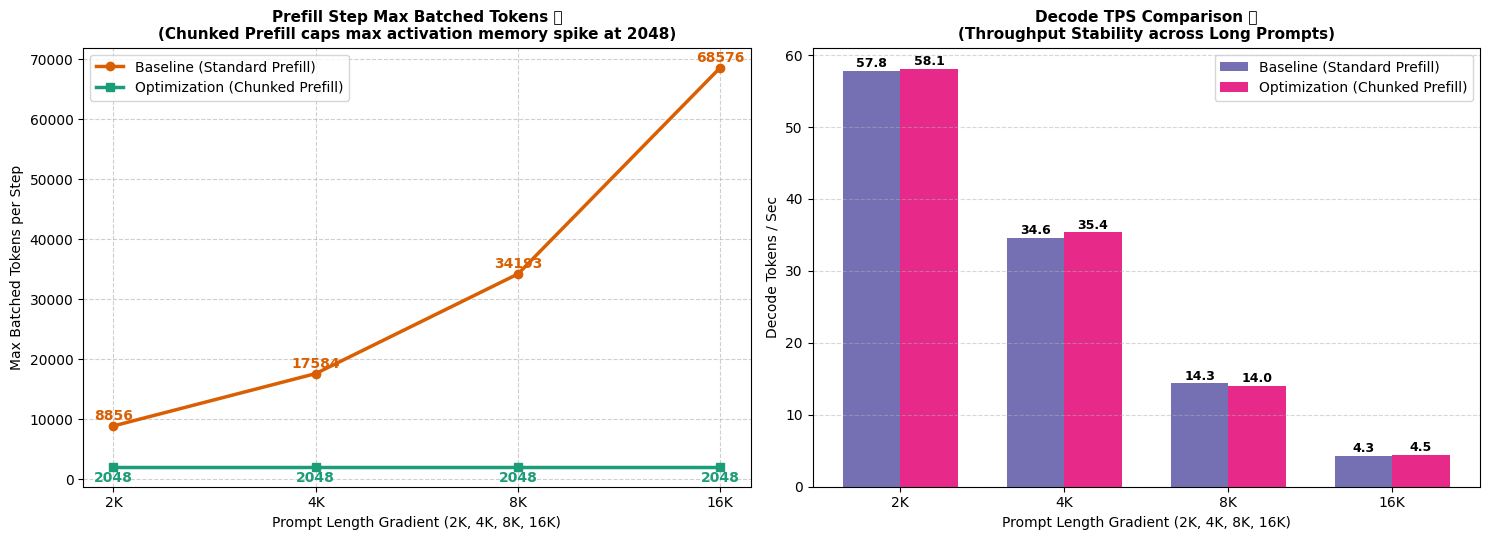


📊 圖表已儲存至: results/charts/day2_chunked_prefill_comparison.png


In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. 載入 JSON 數據
with open("results/raw_logs/day2_baseline.json", "r") as f:
    base_data = json.load(f)

with open("results/raw_logs/day2_chunked_prefill.json", "r") as f:
    chunked_data = json.load(f)

df_base = pd.DataFrame(base_data["metrics"]).assign(mode="Baseline (Standard Prefill)")
df_chunked = pd.DataFrame(chunked_data["metrics"]).assign(mode="Optimization (Chunked Prefill)")
df_all = pd.concat([df_base, df_chunked], ignore_index=True)

# 2. 輸出摘要數據表
print("=================== Day 2: Chunked Prefill 記憶體管理實測總結 ===================")
pivot_tokens = df_all.pivot(index="gradient", columns="mode", values="prefill_step_max_tokens")
pivot_kv_vram = df_all.pivot(index="gradient", columns="mode", values="active_kv_vram_gb")
pivot_tps = df_all.pivot(index="gradient", columns="mode", values="decode_tps")
pivot_lat = df_all.pivot(index="gradient", columns="mode", values="latency_sec")

summary_df = pd.DataFrame({
    "Prefill Max Tokens (Baseline)": pivot_tokens["Baseline (Standard Prefill)"],
    "Prefill Max Tokens (Chunked)": pivot_tokens["Optimization (Chunked Prefill)"],
    "Active KV VRAM (GB)": pivot_kv_vram["Baseline (Standard Prefill)"],
    "Decode TPS (Baseline)": pivot_tps["Baseline (Standard Prefill)"],
    "Decode TPS (Chunked)": pivot_tps["Optimization (Chunked Prefill)"],
    "Latency Baseline (s)": pivot_lat["Baseline (Standard Prefill)"],
    "Latency Chunked (s)": pivot_lat["Optimization (Chunked Prefill)"]
})
print(summary_df.to_markdown())

# 3. 繪製圖表
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x_labels = df_base["gradient"].tolist()

# 圖 1: Prefill 單步 Tokens 峰值 (Chunked Prefill 壓制效果)
axes[0].plot(x_labels, df_base["prefill_step_max_tokens"], marker='o', linewidth=2.5, label="Baseline (Standard Prefill)", color='#D95F02')
axes[0].plot(x_labels, df_chunked["prefill_step_max_tokens"], marker='s', linewidth=2.5, label="Optimization (Chunked Prefill)", color='#1B9E77')
axes[0].set_title('Prefill Step Max Batched Tokens 📉\n(Chunked Prefill caps max activation memory spike at 2048)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Prompt Length Gradient (2K, 4K, 8K, 16K)')
axes[0].set_ylabel('Max Batched Tokens per Step')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

for i, (v1, v2) in enumerate(zip(df_base["prefill_step_max_tokens"], df_chunked["prefill_step_max_tokens"])):
    axes[0].text(i, v1 + 1000, f"{v1}", ha='center', color='#D95F02', fontweight='bold')
    axes[0].text(i, v2 - 2500 if v2 < v1 else v2 + 1000, f"{v2}", ha='center', color='#1B9E77', fontweight='bold')

# 圖 2: Decode TPS 對比
x = range(len(x_labels))
width = 0.35
axes[1].bar([p - width/2 for p in x], df_base["decode_tps"], width, label="Baseline (Standard Prefill)", color='#7570B3')
axes[1].bar([p + width/2 for p in x], df_chunked["decode_tps"], width, label="Optimization (Chunked Prefill)", color='#E7298A')
axes[1].set_title('Decode TPS Comparison 🚀\n(Throughput Stability across Long Prompts)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Prompt Length Gradient (2K, 4K, 8K, 16K)')
axes[1].set_ylabel('Decode Tokens / Sec')
axes[1].set_xticks(x)
axes[1].set_xticklabels(x_labels)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend()

for i, (v1, v2) in enumerate(zip(df_base["decode_tps"], df_chunked["decode_tps"])):
    axes[1].text(i - width/2, v1 + 0.5, f"{v1:.1f}", ha='center', fontsize=9, fontweight='bold')
    axes[1].text(i + width/2, v2 + 0.5, f"{v2:.1f}", ha='center', fontsize=9, fontweight='bold')

chart_path = "results/charts/day2_chunked_prefill_comparison.png"
plt.tight_layout()
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"\n📊 圖表已儲存至: {chart_path}")

### Day 3 : KV cache reuse (prefix caching)

##### 執行 Baseline 實驗

In [ ]:
!python src/experiments/day3_prefix_caching_runner.py --mode baseline --config configs/day3_prefix_caching.yaml

✅ 已成功構建 5 個請求數據集 (data/prompts/day3_dataset.jsonl)：共用 2K System Prompt + 5 個獨立 User Questions
🚀 啟動 vLLM Server (BASELINE 模式, 旗標: --no-enable-prefix-caching)...
📝 伺服器啟動日誌同步寫入: results/logs/vllm_server_baseline.log
✅ vLLM Server 已順利啟動完成！

📢 執行 vLLM 官方 'vllm bench serve' 線上測試...

==================== vLLM Bench Serve 官方線上測試報告 ====================
Namespace(subparser='bench', bench_type='serve', dispatch_function=<function BenchmarkServingSubcommand.cmd at 0x7be9838ccae0>, trust_remote_code=False, seed=0, num_prompts=5, dataset_name='custom', no_stream=False, dataset_path='data/prompts/day3_dataset.jsonl', no_oversample=False, skip_chat_template=False, enable_multimodal_chat=False, disable_shuffle=False, custom_output_len=256, custom_ensure_client_side_data=False, spec_bench_output_len=256, spec_bench_category=None, sharegpt_output_len=None, timed_trace_chunk_hash_size=16, timed_trace_sec_multiplier=1, timed_trace_label_timestamp='timestamp', timed_trace_label_input_length='input_length', 

##### 執行優化實驗

In [ ]:
!python src/experiments/day3_prefix_caching_runner.py --mode apc --config configs/day3_prefix_caching.yaml

✅ 已成功構建 5 個請求數據集 (data/prompts/day3_dataset.jsonl)：共用 2K System Prompt + 5 個獨立 User Questions
🚀 啟動 vLLM Server (APC 模式, 旗標: --enable-prefix-caching)...
📝 伺服器啟動日誌同步寫入: results/logs/vllm_server_apc.log
✅ vLLM Server 已順利啟動完成！

📢 執行 vLLM 官方 'vllm bench serve' 線上測試...

==================== vLLM Bench Serve 官方線上測試報告 ====================
Namespace(subparser='bench', bench_type='serve', dispatch_function=<function BenchmarkServingSubcommand.cmd at 0x7d0dc04785e0>, trust_remote_code=False, seed=0, num_prompts=5, dataset_name='custom', no_stream=False, dataset_path='data/prompts/day3_dataset.jsonl', no_oversample=False, skip_chat_template=False, enable_multimodal_chat=False, disable_shuffle=False, custom_output_len=256, custom_ensure_client_side_data=False, spec_bench_output_len=256, spec_bench_category=None, sharegpt_output_len=None, timed_trace_chunk_hash_size=16, timed_trace_sec_multiplier=1, timed_trace_label_timestamp='timestamp', timed_trace_label_input_length='input_length', timed_trace_l

##### 生成對比圖表

====================== Day 3 實驗結果總結 ======================
             Mode  TTFT Avg (ms)  TTFT P99 (ms) Cache Hits / Queries Cache Hit Rate (%)
Baseline (No APC)        7388.60        8560.20                0 / 0               0.0%
      APC Enabled         827.25        1804.98         8512 / 11196             76.03%


/tmp/ipykernel_1076/636806967.py:66: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1076/636806967.py:66: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1076/636806967.py:69: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/tmp/ipykernel_1076/636806967.py:69: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


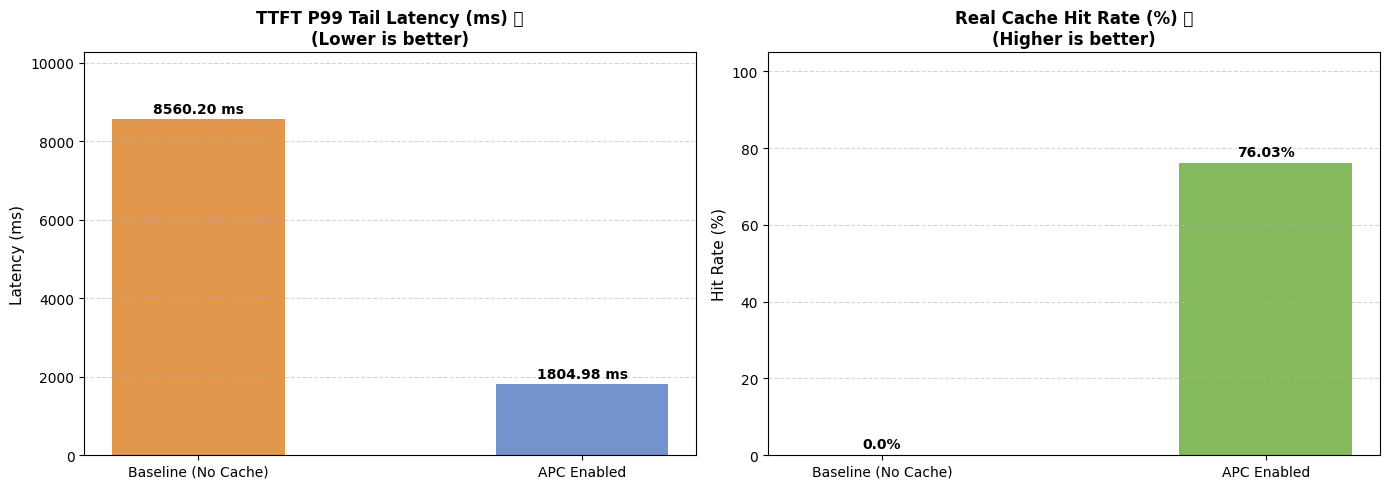


📊 圖表已成功儲存至: results/charts/day3_apc_comparison.png


In [3]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. 讀取 JSON 結果
with open("results/raw_logs/day3_baseline.json", "r", encoding="utf-8") as f:
    base_res = json.load(f)

with open("results/raw_logs/day3_apc.json", "r", encoding="utf-8") as f:
    apc_res = json.load(f)

# 2. 輸出文字版摘要對照表
df_summary = pd.DataFrame([
    {
        "Mode": "Baseline (No APC)",
        "TTFT Avg (ms)": base_res["ttft_avg_ms"] if base_res["ttft_avg_ms"] is not None else "請參閱主機 stdout",
        "TTFT P99 (ms)": base_res["ttft_p99_ms"] if base_res["ttft_p99_ms"] is not None else "請參閱主機 stdout",
        "Cache Hits / Queries": f"{base_res['cache_hits']} / {base_res['cache_queries']}",
        "Cache Hit Rate (%)": f"{base_res['cache_hit_rate_pct']}%"
    },
    {
        "Mode": "APC Enabled",
        "TTFT Avg (ms)": apc_res["ttft_avg_ms"] if apc_res["ttft_avg_ms"] is not None else "請參閱主機 stdout",
        "TTFT P99 (ms)": apc_res["ttft_p99_ms"] if apc_res["ttft_p99_ms"] is not None else "請參閱主機 stdout",
        "Cache Hits / Queries": f"{apc_res['cache_hits']} / {apc_res['cache_queries']}",
        "Cache Hit Rate (%)": f"{apc_res['cache_hit_rate_pct']}%"
    }
])

print("====================== Day 3 實驗結果總結 ======================")
print(df_summary.to_string(index=False))

# 3. 繪製對比圖表
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
modes = ['Baseline (No Cache)', 'APC Enabled']

# (A) TTFT P99 尾端延遲比較
p99_base = base_res["ttft_p99_ms"] if isinstance(base_res["ttft_p99_ms"], (int, float)) else 0
p99_apc = apc_res["ttft_p99_ms"] if isinstance(apc_res["ttft_p99_ms"], (int, float)) else 0
p99_values = [p99_base, p99_apc]

axes[0].bar(modes, p99_values, color=['#E1974C', '#7293CB'], width=0.45)
axes[0].set_title('TTFT P99 Tail Latency (ms) 📉\n(Lower is better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Latency (ms)', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

max_p99 = max(p99_values)
if max_p99 > 0:
    axes[0].set_ylim(0, max_p99 * 1.20)

for i, v in enumerate(p99_values):
    if v > 0:
        axes[0].text(i, v + (max(p99_values)*0.02 if max(p99_values) > 0 else 1), f"{v:.2f} ms", ha='center', fontweight='bold')

# (B) 真實快取命中率 (Cache Hit Rate %)
hit_rates = [base_res["cache_hit_rate_pct"], apc_res["cache_hit_rate_pct"]]
axes[1].bar(modes, hit_rates, color=['#E1974C', '#84BA5B'], width=0.45)
axes[1].set_title('Real Cache Hit Rate (%) 🎯\n(Higher is better)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Hit Rate (%)', fontsize=11)
axes[1].set_ylim(0, 105)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(hit_rates):
    axes[1].text(i, v + 2, f"{v}%", ha='center', fontweight='bold')

plt.tight_layout()
os.makedirs("results/charts", exist_ok=True)
chart_path = "results/charts/day3_apc_comparison.png"
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"\n📊 圖表已成功儲存至: {chart_path}")

### Day 4: KV cache offloading

##### 安裝監測kv cache block套件

In [ ]:
!pip install pynvml nvidia-ml-py

##### 執行 Baseline 實驗

In [ ]:
!python src/experiments/day4_offload_runner.py --mode baseline --config configs/day4_kv_offloading.yaml

/usr/local/lib/python3.13/dist-packages/torch/cuda/__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
\n==================================================
🚀 [Day 4] Mode: BASELINE | CPU KV Swap Space: 0 GB | Weight Offload: 0 GB
(MainProcess pid=10969) INFO 10-27 12:26:20 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'max_model_len': 4096, 'gpu_memory_utilization': 0.58, 'max_num_seqs': 256, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=10969) WARNING 10-27 12:26:20 [interface.py:1457] Unknown vLLM environment variable detected: VLLM_USE_V1
(MainProcess pid=10969) INFO 10-27 12:26:22 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=10969) WARNING 10-27 12:26:22 [model.py:2439]

##### 執行優化實驗

In [ ]:
!python src/experiments/day4_offload_runner.py --mode offload --config configs/day4_kv_offloading.yaml

/usr/local/lib/python3.13/dist-packages/torch/cuda/__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
\n==================================================
🚀 [Day 4] Mode: OFFLOAD | CPU KV Swap Space: 8 GB | Weight Offload: 0 GB
(MainProcess pid=11807) INFO 10-27 12:28:50 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'max_model_len': 4096, 'gpu_memory_utilization': 0.58, 'max_num_seqs': 256, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=11807) WARNING 10-27 12:28:50 [interface.py:1457] Unknown vLLM environment variable detected: VLLM_USE_V1
(MainProcess pid=11807) INFO 10-27 12:28:52 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=11807) WARNING 10-27 12:28:52 [model.py:2439] 

##### 生成對比圖表

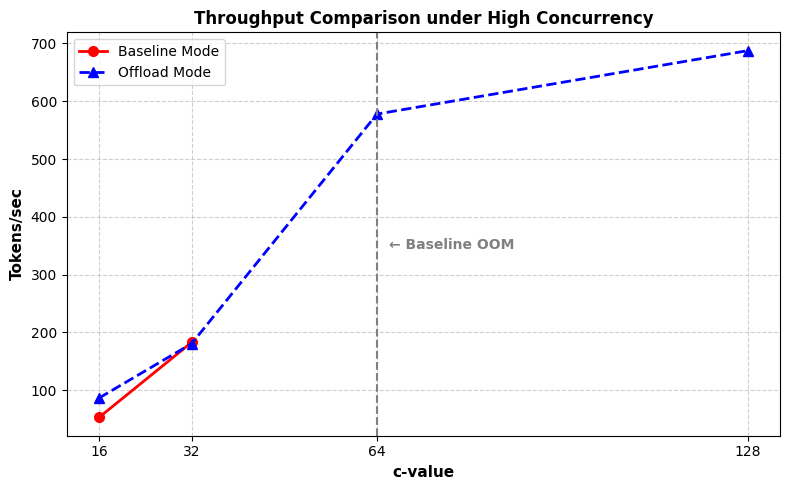

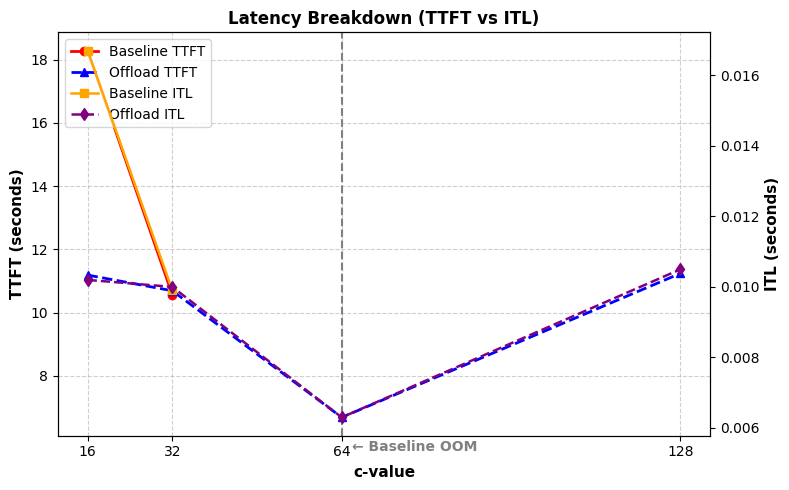

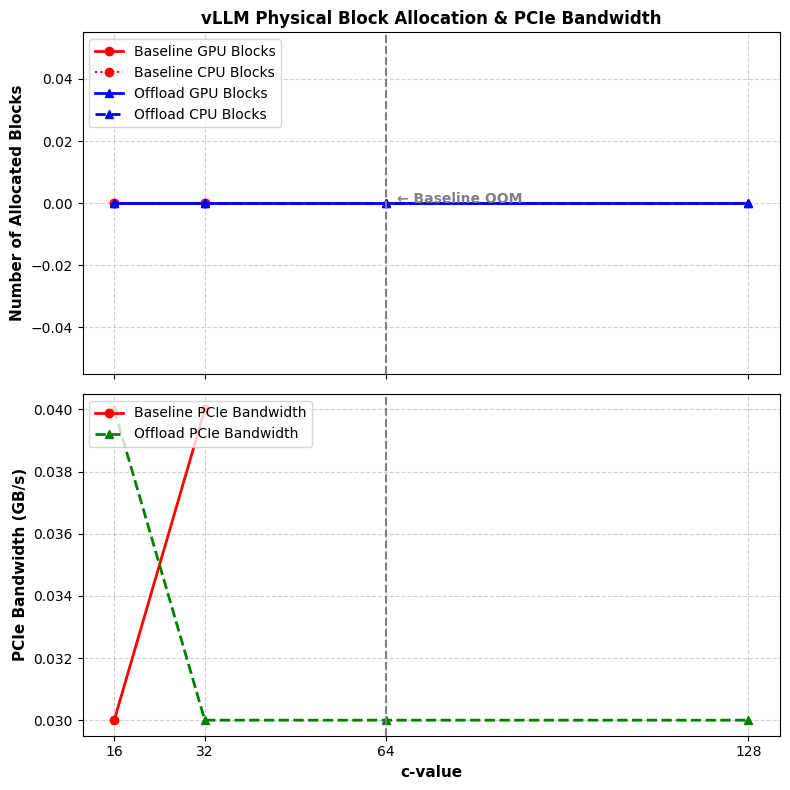

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np

# 1. 讀取 raw_logs 數據
with open("results/raw_logs/day4_baseline.json", "r", encoding="utf-8") as f:
  base_json = json.load(f)
with open("results/raw_logs/day4_offload.json", "r", encoding="utf-8") as f:
  offload_json = json.load(f)

c_values = [16, 32, 64, 128]


def extract_metric(json_data, key):
  res = []
  for item in json_data["results"]:
    val = item.get(key)
    res.append(
        val if (val is not None and item.get("success", False)) else np.nan
    )
  return np.array(res, dtype=float)


# 提取指標數據
base_tps = extract_metric(base_json, "throughput_tps")
base_ttft = extract_metric(base_json, "ttft_s")
base_itl = extract_metric(base_json, "itl_s")
base_gpu_b = extract_metric(base_json, "gpu_blocks")
base_cpu_b = extract_metric(base_json, "cpu_blocks")
base_pcie = extract_metric(base_json, "pcie_bw_gbps")

offload_tps = extract_metric(offload_json, "throughput_tps")
offload_ttft = extract_metric(offload_json, "ttft_s")
offload_itl = extract_metric(offload_json, "itl_s")
offload_gpu_b = extract_metric(offload_json, "gpu_blocks")
offload_cpu_b = extract_metric(offload_json, "cpu_blocks")
offload_pcie = extract_metric(offload_json, "pcie_bw_gbps")

# 視覺化學術風格設定
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "font.size": 10})
oom_x = 64  # 設定 Baseline 觸發 OOM 的臨界點為 c=64

# ==============================================================================
# 圖一：吞吐量對比圖 (Throughput)
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(
    c_values,
    base_tps,
    label="Baseline Mode",
    color="red",
    linestyle="-",
    marker="o",
    linewidth=2,
    markersize=7,
)
ax1.plot(
    c_values,
    offload_tps,
    label="Offload Mode",
    color="blue",
    linestyle="--",
    marker="^",
    linewidth=2,
    markersize=7,
)

ax1.axvline(x=oom_x, color="gray", linestyle="--", linewidth=1.5)
ax1.text(
    oom_x + 2,
    (
        np.nanmax(offload_tps) * 0.5
        if not np.isnan(np.nanmax(offload_tps))
        else 50
    ),
    "← Baseline OOM",
    color="gray",
    fontweight="bold",
)

ax1.set_title(
    "Throughput Comparison under High Concurrency",
    fontsize=12,
    fontweight="bold",
)
ax1.set_xlabel("c-value", fontsize=11, fontweight="bold")
ax1.set_ylabel("Tokens/sec", fontsize=11, fontweight="bold")
ax1.set_xticks(c_values)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper left")
fig1.tight_layout()
fig1.savefig("results/charts/day4_throughput.png", dpi=300)
plt.show()

# ==============================================================================
# 圖二：時延拆解圖 (Latency - TTFT/ITL)
# ==============================================================================
fig2, ax2_ttft = plt.subplots(figsize=(8, 5))
ax2_itl = ax2_ttft.twinx()

# 左 Y 軸：TTFT (seconds)
line1 = ax2_ttft.plot(
    c_values,
    base_ttft,
    label="Baseline TTFT",
    color="red",
    linestyle="-",
    marker="o",
    linewidth=2,
)
line2 = ax2_ttft.plot(
    c_values,
    offload_ttft,
    label="Offload TTFT",
    color="blue",
    linestyle="--",
    marker="^",
    linewidth=2,
)
ax2_ttft.set_ylabel("TTFT (seconds)", fontsize=11, fontweight="bold")

# 右 Y 軸：ITL (seconds) - 橘色與紫色對比
line3 = ax2_itl.plot(
    c_values,
    base_itl,
    label="Baseline ITL",
    color="orange",
    linestyle="-",
    marker="s",
    linewidth=1.8,
)
line4 = ax2_itl.plot(
    c_values,
    offload_itl,
    label="Offload ITL",
    color="purple",
    linestyle="--",
    marker="d",
    linewidth=1.8,
)
ax2_itl.set_ylabel("ITL (seconds)", fontsize=11, fontweight="bold")

lines = line1 + line2 + line3 + line4
labels = [l.get_label() for l in lines]
ax2_ttft.legend(lines, labels, loc="upper left")

ax2_ttft.axvline(x=oom_x, color="gray", linestyle="--", linewidth=1.5)
ax2_ttft.text(
    oom_x + 2,
    (
        np.nanmax(offload_ttft) * 0.5
        if not np.isnan(np.nanmax(offload_ttft))
        else 1.0
    ),
    "← Baseline OOM",
    color="gray",
    fontweight="bold",
)

ax2_ttft.set_title(
    "Latency Breakdown (TTFT vs ITL)", fontsize=12, fontweight="bold"
)
ax2_ttft.set_xlabel("c-value", fontsize=11, fontweight="bold")
ax2_ttft.set_xticks(c_values)
ax2_ttft.grid(True, linestyle="--", alpha=0.6)
fig2.tight_layout()
fig2.savefig("results/charts/day4_latency.png", dpi=300)
plt.show()

# ==============================================================================
# 圖三：vLLM Block 與頻寬監控圖 (vLLM Block & Bandwidth)
# ==============================================================================
fig3, (ax3_top, ax3_bottom) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# 上方子圖：Number of Allocated Blocks
ax3_top.plot(
    c_values,
    base_gpu_b,
    label="Baseline GPU Blocks",
    color="red",
    linestyle="-",
    marker="o",
    linewidth=2,
)
ax3_top.plot(
    c_values,
    base_cpu_b,
    label="Baseline CPU Blocks",
    color="red",
    linestyle=":",
    marker="o",
    linewidth=1.5,
)
ax3_top.plot(
    c_values,
    offload_gpu_b,
    label="Offload GPU Blocks",
    color="blue",
    linestyle="-",
    marker="^",
    linewidth=2,
)
ax3_top.plot(
    c_values,
    offload_cpu_b,
    label="Offload CPU Blocks",
    color="blue",
    linestyle="--",
    marker="^",
    linewidth=2,
)

ax3_top.axvline(x=oom_x, color="gray", linestyle="--", linewidth=1.5)
ax3_top.text(
    oom_x + 2,
    (
        np.nanmax(offload_cpu_b) * 0.7
        if not np.isnan(np.nanmax(offload_cpu_b))
        else 100
    ),
    "← Baseline OOM",
    color="gray",
    fontweight="bold",
)
ax3_top.set_title(
    "vLLM Physical Block Allocation & PCIe Bandwidth",
    fontsize=12,
    fontweight="bold",
)
ax3_top.set_ylabel("Number of Allocated Blocks", fontsize=11, fontweight="bold")
ax3_top.grid(True, linestyle="--", alpha=0.6)
ax3_top.legend(loc="upper left")

# 下方子圖：PCIe Bandwidth (GB/s)
ax3_bottom.plot(
    c_values,
    base_pcie,
    label="Baseline PCIe Bandwidth",
    color="red",
    linestyle="-",
    marker="o",
    linewidth=2,
)
ax3_bottom.plot(
    c_values,
    offload_pcie,
    label="Offload PCIe Bandwidth",
    color="green",
    linestyle="--",
    marker="^",
    linewidth=2,
)

ax3_bottom.axvline(x=oom_x, color="gray", linestyle="--", linewidth=1.5)
ax3_bottom.set_xlabel("c-value", fontsize=11, fontweight="bold")
ax3_bottom.set_ylabel("PCIe Bandwidth (GB/s)", fontsize=11, fontweight="bold")
ax3_bottom.set_xticks(c_values)
ax3_bottom.grid(True, linestyle="--", alpha=0.6)
ax3_bottom.legend(loc="upper left")

fig3.tight_layout()
fig3.savefig("results/charts/day4_blocks_bandwidth.png", dpi=300)
plt.show()